# PLN Projeto 2 - Extração de grafo de conhecimento clínico com N-grams e ML

**Pipeline**

1. Pré-processamento e gazetteer (vindo da Parte 1) com *matcher* de frases por maior casamento.
2. Análise de N-grams (frequência, PMI/NPMI) para descobrir entidades compostas candidatas.
3. NER como etiquetagem de sequências (CRF) com supervisão fraca: rótulos gerados pelo gazetteer.
4. Experimento de generalização: parte do léxico é escondida no treino; mede-se se o CRF recupera termos nunca vistos.
5. Classificação de relações entre pares de entidades (TF-IDF de N-grams + LogReg / ComplementNB / LinearSVC), também com supervisão fraca.
6. Descoberta de padrões de relação (n-grams discriminativos) e de gatilhos novos.
7. Construção do grafo (regras × ML), métricas estruturais e visualização.

Dependências: `pip install scikit-learn sklearn-crfsuite networkx matplotlib pandas`

In [64]:
import os, re, random, math, json
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED)

CASES_PATH = "../../data/external/cases.csv"
META_PATH  = "../../data/external/metadata.csv"   # opcional
OUT_DIR    = "../../data/processed"
os.makedirs(OUT_DIR, exist_ok=True)

TEST_SIZE      = 0.2    # divisão por artigo (evita vazamento entre casos do mesmo artigo)
NEG_KEEP       = 0.3    # fração de sentenças sem entidade mantidas no treino do CRF
HIDE_FRAC      = 0.25   # fração do léxico escondida no experimento de generalização
HIDE_MIN_COUNT = 3      # só esconde termos com >= N ocorrências no treino
MAX_BETWEEN    = 10     # máx. de tokens entre duas entidades para formar um par de relação

## 1. Dados

In [65]:
df = pd.read_csv(CASES_PATH).dropna(subset=['case_text']).drop_duplicates('case_id')
if os.path.exists(META_PATH):
    df = df.merge(pd.read_csv(META_PATH), on='article_id', how='left', suffixes=('', '_meta'))
df = df.reset_index(drop=True)

# Divide os artigos em grupo de teste (0.2) e treino (0.8), evitando vazamento entre casos do mesmo artigo
# ao tratar cada 'article_id' como um grupo indivisível
from sklearn.model_selection import GroupShuffleSplit
tr_idx, te_idx = next(GroupShuffleSplit(1, test_size=TEST_SIZE, random_state=SEED).split(df, groups=df['article_id']))
df_train, df_test = df.iloc[tr_idx].reset_index(drop=True), df.iloc[te_idx].reset_index(drop=True)
print(f"{len(df)} casos | treino: {len(df_train)} | teste: {len(df_test)}")

56 casos | treino: 45 | teste: 11


## 2. Pré-processamento e matcher de entidades

Mudanças em relação à Parte 1:

- **Matcher por frase**: a Parte 1 indexava *cada token* de um termo composto, então `acute`, `blood` ou `count` disparavam entidades isoladas e o último termo lido sobrescrevia os anteriores. Agora o casamento é por sequência de *stems*, com maior casamento à esquerda.
- **Tokenização** preserva hifens e alfanuméricos (`x-ray`, `c-reactive`, `hba1c`, `pd-l1`, `fev1`), que antes eram quebrados.
- **Resultados de exames** são extraídos por regex sobre o texto (unidade `U/L` era quebrada pelo tokenizador).
- IDs de nós determinísticos e processamento em lote (antes só `df.iloc[6]`).

In [66]:
TOKEN_RE = re.compile(r"""
    \d+(?:\.\d+)?
    |[A-Za-zÀ-ÿ][A-Za-zÀ-ÿ0-9]*(?:[-'][A-Za-zÀ-ÿ0-9]+)*
    |[.,;:!?()%/\[\]=<>+-]
""", re.VERBOSE)
def tokenize(sent):
    """Tokenização por regex, preserva hífens e alfanuméricos"""
    return [(m.group(), m.start(), m.end()) for m in TOKEN_RE.finditer(sent)]

STEM_RE = re.compile(r'(?<!s)s$')
def stem(tok):
    """Stemming por regex, remove um s no final, exceto ss"""
    return STEM_RE.sub('', tok.lower())

def split_sentences(text):
    """Separação do texto em sentenças por regex, 
    cortando a partir de .!? seguidos de espaço e letra maiúscula ou número"""
    return [s for s in re.split(r'(?<=[.!?])\s+(?=[A-Z0-9])', text.strip()) if s]

In [67]:
def build_gazetteers():
    return {
        'Diagnosis': ['diabetes mellitus', 'hypertension', 'acute pancreatitis', 'chronic pancreatitis', 'pancreatic pseudocyst', 'pseudocyst', 'solid mass', 'type 2 diabetes', 'tumor', 'cancer',
            'acute respiratory distress syndrome', 'sepsis', 'septic shock', 'pneumonia', 'pulmonary embolism', 'acute heart failure', 'congestive heart failure', 'myocardial infarction',
            'ischemic stroke', 'hemorrhagic stroke', 'acute kidney injury', 'chronic kidney disease', 'renal failure', 'acute liver failure', 'cirrhosis', 'hepatitis',
            'cholangitis', 'biliary obstruction', 'appendicitis', 'peritonitis', 'gastrointestinal bleeding', 'intestinal obstruction', 'peptic ulcer disease',
            'deep vein thrombosis', 'venous thromboembolism', 'anemia', 'thrombocytopenia', 'leukemia', 'lymphoma', 'hemolytic anemia', 'fatty liver disease',
            'metastatic disease', 'meningitis', 'encephalitis', 'pyelonephritis', 'urinary tract infection', 'bronchitis', 'asthma', 'pneumonitis', 'respiratory failure',
            'arrhythmia', 'atrial fibrillation', 'valvular disease', 'endocarditis', 'pericarditis', 'liver abscess', 'splenomegaly'
        ],
        'Symptom': ['epigastric pain', 'nausea', 'fever', 'epigastric tenderness', 'fat stranding', 'pain', 'headache', 'cough',
            'abdominal pain', 'vomiting', 'diarrhea', 'constipation', 'bloody stools', 'hematochezia', 'melena', 'shortness of breath', 'dyspnea', 'wheezing',
            'chest pain', 'palpitations', 'dizziness', 'syncope', 'fatigue', 'weakness', 'malaise', 'loss of appetite', 'anorexia', 'weight loss', 'weight gain',
            'swelling', 'edema', 'leg swelling', 'lower extremity edema', 'jaundice', 'dark urine', 'itching', 'pruritus', 'confusion', 'delirium', 'sleep disturbance',
            'insomnia', 'restlessness', 'anxiety', 'depression', 'tremor', 'muscle weakness', 'myalgia', 'arthralgia', 'back pain', 'joint pain', 'neck pain',
            'sore throat', 'hoarseness', 'hemoptysis', 'cyanosis', 'hematuria', 'dysuria', 'polyuria', 'oliguria', 'urinary retention', 'flank pain', 'cold intolerance',
            'heat intolerance', 'blurred vision', 'visual disturbance', 'vertigo', 'paresthesia', 'numbness', 'tingling', 'bruising', 'easy bruising', 'bleeding', 'nosebleed',
            'productive cough', 'nonproductive cough', 'dysphagia', 'odynophagia', 'hiccups', 'tachycardia', 'hypotension', 'hypertension symptoms', 'chills', 'rigors', 'sweating',
            'night sweats', 'burning sensation', 'pressure sensation', 'abdominal distension', 'bloating', 'gastroesophageal reflux', 'heartburn', 'dyspepsia', 'gastrointestinal pain', 'thirst',
            'polyuria', 'excessive thirst', 'hyperglycemia symptoms', 'hypoglycemia symptoms', 'fainting'
        ],
        'Exam': [
          'computed tomography', 'ct', 'thoracic ct', 'endoscopic ultrasound', 'eus', 'ultrasound', 'laboratory tests', 'mri', 'x-ray', 'echocardiogram', 'echocardiography', 'ecg', 'flow cytometry',
          'hemoglobin', 'hematocrit', 'white blood cell count', 'total leukocyte count', 'leucocytosis', 'lymphocyte count', 'platelet count', 'platelet counts', 'mean corpuscular volume', 
          'reticulocyte count', 'haptoglobin', 'adamts13 activity', 'c-reactive protein', 'crp', 'erythrocyte sedimentation rate', 'esr', 'creatinine', 'serum creatinine', 'albumin', 'total protein',
          'ferritin', 'lactate dehydrogenase', 'ldh', 'complement c3', 'complement c4', 'c3', 'c4', 'troponin', 'troponin i', 'ck-mb', 'creatine kinase', 'myoglobin', 'ejection fraction', 'lvef', 
          'mean gradient', 'nt-probnp', 'heart rate', 'blood pressure', 'mean arterial blood pressure', 'glycosylated hemoglobin', 'hemoglobin a1c', 'hba1c', 'blood sugar', 'immunoglobulin m', 
          'immunoglobulin g', 'igm', 'igg', 'igg levels', 'forced vital capacity', 'fvc', 'forced expiratory volume', 'fev1', 'diffusing capacity', 'dlco', 'oxygen saturation', 'respiratory rate', 
          'carcinoembryonic antigen', 'cea', 'pd-l1 tps score','hydroxychloroquine level', 'gtt',
      ],
        'Treatment': [
            'intravenous fluids', 'oral rehydration', 'analgesia', 'analgesics', 'pain control',
            'antibiotics', 'antiviral therapy', 'antifungal therapy', 'antiparasitic therapy',
            'anticoagulation', 'antiplatelet therapy', 'heparin', 'warfarin', 'enoxaparin',
            'insulin', 'metformin', 'glucose control', 'blood pressure control', 'antihypertensive therapy',
            'fluid resuscitation', 'electrolyte replacement', 'oxygen therapy', 'ventilation support',
            'corticosteroids', 'prednisone', 'hydrocortisone', 'dexamethasone', 'steroid therapy',
            'immunosuppressive therapy', 'plasma exchange', 'plasmapheresis', 'intravenous immunoglobulin', 'ivig',
            'chemotherapy', 'radiotherapy', 'targeted therapy', 'immunotherapy', 'hormonal therapy',
            'surgery', 'laparotomy', 'laparoscopy', 'resection', 'drainage', 'debridement',
            'endoscopic drainage', 'cystgastrostomy', 'gastrojejunostomy', 'stent placement', 'biliary drainage',
            'dialysis', 'renal replacement therapy', 'liver transplant', 'kidney transplant', 'transplantation',
            'blood transfusion', 'platelet transfusion', 'erythrocyte transfusion',
            'physical therapy', 'rehabilitation', 'respiratory physiotherapy', 'occupational therapy',
            'bronchodilator therapy', 'inhaled beta agonist', 'nebulized therapy', 'smoking cessation',
            'prophylactic antibiotics', 'empiric therapy', 'supportive care', 'palliative care',
            'nutritional support', 'enteral nutrition', 'parenteral nutrition', 'oral nutrition',
            'thrombolysis', 'vasopressor support', 'inotropic support', 'antiemetics', 'anti-inflammatory therapy',
            'antihistamines', 'acid suppression', 'proton pump inhibitor', 'ppi', 'antacids',
            'beta-blocker therapy', 'statin therapy', 'aspirin', 'ibuprofen', 'acetaminophen', 'paracetamol',
            'antidepressant therapy', 'antiepileptic therapy', 'antiarrhythmic therapy', 'diuretic therapy',
            'vaccination', 'immunization', 'monitoring', 'observation', 'watchful waiting', 'conservative management'
        ]
    }

In [68]:
ENT_TYPES = ['Diagnosis', 'Symptom', 'Exam', 'Treatment']
COND = {'Diagnosis', 'Symptom'}

def build_phrase_index(gaz):
    """Construção de índice de busca para casamento de entidades, 
    Cada termo é tokenizado e cada token vira seu stem. 
    O valor é (tipo, termo_original). 
    \nRetorna (index, max_len), onde max_len é o tamanho do maior termo."""
    index, max_len = {}, 1
    for etype, kws in gaz.items():
        for kw in kws:
            key = tuple(stem(t[0]) for t in tokenize(kw))
            if key and key not in index:
                index[key] = (etype, kw)
                max_len = max(max_len, len(key))
    return index, max_len

def match_entities(tokens, index, max_len):
    """Percorre uma sentença da esquerda para a direita,
    usa janelas de tamanho max_len...1 e consulta a tupla stems[i:i+n] no índice.
    No primeiro acerto (maior janela), registra o span e avança.
    \nRetorna [(início, fim, tipo, termo_original)]."""
    stems = [stem(t[0]) for t in tokens]
    i, spans = 0, []
    while i < len(tokens):
        for n in range(min(max_len, len(tokens) - i), 0, -1):
            hit = index.get(tuple(stems[i:i + n]))
            if hit:
                spans.append((i, i + n, hit[0], hit[1]))
                i += n
                break
        else:
            i += 1
    return spans

def spans_to_bio(n, spans):
    """Converte spans em tags Begin, Inside, Outside (BIO).
    Começa com O (Outside) para todos, marca o primeiro token do span com B-TIPO (Begin) 
    e os demais com I-TIPO (Inside)
    \nRetorna lista de tags no formato ['O', 'B-TIPO', 'I-TIPO', ...]"""
    tags = ['O'] * n
    for s, e, t, *_ in spans:
        tags[s] = f'B-{t}'
        for k in range(s + 1, e):
            tags[k] = f'I-{t}'
    return tags

def bio_to_spans(tags):
    """Converte tags BIO em spans (início, fim, tipo).
    Começa um span a partir de uma tag B-TIPO, 
    continua enquanto houver I-TIPO do mesmo tipo, 
    e fecha o span quando encontra O ou B-TIPO de outro tipo.
    \nRetorna lista de spans no formato [(início, fim, tipo)]."""
    spans, start, typ = [], None, None
    for i, tag in enumerate(list(tags) + ['O']):
        if tag == 'O' or tag.startswith('B-') or tag[2:] != typ:
            if typ is not None:
                spans.append((start, i, typ))
            start, typ = (i, tag[2:]) if tag != 'O' else (None, None)
    return spans

### Corpus em nível de sentença

- `gold`: entidades pelo gazetteer **completo** (usado como referência *silver*).
- `rules`: baseline da Parte 1 usando o gazetteer **reduzido** (sem os termos escondidos).
- O CRF é treinado com os rótulos do gazetteer reduzido e avaliado contra `gold`. Isso mede se ele recupera termos que as regras não conhecem.

In [69]:
def make_sentences(dfc):
    """Separa o case_text de cada caso em sentenças, 
    cortando-o a partir de uma heurísitca definida em split_sentences().
    Guarda um dicionário para cada sentença com case_id, article_id, sid (sentença id), 
    text (texto da sentença) e tokens (lista de tuplas (token, início, fim)).
    \nRetorna lista de dicionários [{'case_id': ..., 'article_id': ..., 'sid': ..., 'text': ..., 'tokens': ...}, ...]
    """
    out = []
    for r in dfc.itertuples():
        for sid, sent in enumerate(split_sentences(r.case_text)):
            toks = tokenize(sent)
            if toks:
                out.append({'case_id': r.case_id, 'article_id': r.article_id, 'sid': sid, 'text': sent, 'tokens': toks})
    return out

sents_train, sents_test = make_sentences(df_train), make_sentences(df_test)

GAZ = build_gazetteers()
FULL_INDEX, FULL_MAXLEN = build_phrase_index(GAZ)
# Produz um matcher de entidades para todas as sentenças, usando o gazetteer completo
for s in sents_train + sents_test:
    s['gold'] = match_entities(s['tokens'], FULL_INDEX, FULL_MAXLEN)

# Léxico escondido (experimento de generalização)
kw_counts = Counter(sp[3] for s in sents_train for sp in s['gold'])  # Conta, no treino, quantas vezes cada termo original aparece em 'gold'
eligible = sorted(k for k, c in kw_counts.items() if c >= HIDE_MIN_COUNT)  # Seleciona os termos com mais de 3 ocorrências
HIDDEN = set(random.Random(SEED).sample(eligible, int(HIDE_FRAC * len(eligible))))  # Sorteia 25% dos termos elegíveis para esconder
GAZ_RED = {t: [k for k in kws if k not in HIDDEN] for t, kws in GAZ.items()}  # Faz um gazetteer reduzido, removendo os termos sorteados para esconder
RED_INDEX, RED_MAXLEN = build_phrase_index(GAZ_RED)

# Produz um matcher de entidades para todas as senteças, usando o gazetter reduzido
for s in sents_train + sents_test:
    s['rules'] = match_entities(s['tokens'], RED_INDEX, RED_MAXLEN)

print(f"sentenças treino/teste: {len(sents_train)}/{len(sents_test)}")
print(f"termos do gazetteer vistos no treino: {len(kw_counts)} | elegíveis: {len(eligible)} | escondidos: {len(HIDDEN)}")
print("exemplos escondidos:", sorted(HIDDEN)[:10])

sentenças treino/teste: 1199/257
termos do gazetteer vistos no treino: 159 | elegíveis: 73 | escondidos: 18
exemplos escondidos: ['albumin', 'antibiotics', 'anticoagulation', 'appendicitis', 'cancer', 'chemotherapy', 'chest pain', 'creatinine', 'enteral nutrition', 'fatigue']


## 3. Análise de N-grams: frequência, PMI e NPMI

$$\mathrm{PMI}(x,y)=\log_2\frac{P(x,y)}{P(x)\,P(y)}\qquad
\mathrm{NPMI}(x,y)=\frac{\mathrm{PMI}(x,y)}{-\log_2 P(x,y)}\in[-1,1]$$

Para trigramas $(x,y,z)$ usa-se o menor NPMI entre as duas partições $(xy,\,z)$ e $(x,\,yz)$, tratando o bigrama como unidade, o que mantém a escala em $[-1,1]$. As probabilidades são estimadas por máxima verossimilhança sobre o **treino**.

PMI (Pointwise Mutual Information) mede quanto duas palavras ocorrem juntas além do esperado se fossem independentes. PMI = 0 indica independência, PMI > 0 indica atração e PMI < 0 indica repulsão.

O NPMI é o valor normalizado do PMI, entre [-1, 1]. Evita o viés do PMI bruto em favor de n-grams raros. Candidatos com NPMI alto e contagem mínima são expressões fortemente associadas (`myocardial infarction`).

In [70]:
# Lista de stopwords para filtrar n-gramas
STOP = set("""a an the of in on at to for with by from and or but as is was were are be been being has have had
this that these those it its he she her his their there then than which who whom after before during without
patient patients year years old day days month months week weeks hour hours""".split())
# Regex para filtrar palavras válidas (começa com letra, pode ter números, hífens e apóstrofos)
WORD_RE = re.compile(r"[a-z][a-z0-9\-']*")

def _ok(w):
    """Filtra a palavra w sobre um regex e stopwords
    \nRetorna True se a palavra w for válida, False caso contrário."""
    return WORD_RE.fullmatch(w) is not None and w not in STOP

def collocations(sents, min_count=5):
    """Recebe as sentenças do treino e calcula n-gramas de 2 e 3 palavras, 
    filtrando por stopwords e regex.
    \nRetorna um DataFrame com as colunas ['ngram', 'n', 'count', 'pmi', 'npmi'], ordenado por NPMI decrescente."""
    # uni é a frequência de cada token,
    # raw_bi é a frequência de cada bigrama bruto (sem filtro),
    # bi é a frequência de cada bigrama filtrado (sem stopwords e regex),
    # tri é a frequência de cada trigram filtrado (sem stopwords e regex, 
    # com o token do meio podendo ser stopword, mas deve passar no regex)
    uni, raw_bi, bi, tri = Counter(), Counter(), Counter(), Counter()
    for s in sents:
        ws = [t[0].lower() for t in s['tokens']]
        uni.update(ws)
        raw_bi.update(zip(ws, ws[1:]))
        bi.update((a, b) for a, b in zip(ws, ws[1:]) if _ok(a) and _ok(b))
        tri.update((a, b, c) for a, b, c in zip(ws, ws[1:], ws[2:])
                   if _ok(a) and _ok(c) and WORD_RE.fullmatch(b))
        
    N = sum(uni.values())
    P = lambda c: c / N

    def npmi(p_xyz, p_a, p_b):
        """Calcula e retorna o PMI e NPMI de um n-grama"""
        pmi = math.log2(p_xyz / (p_a * p_b))
        return pmi, pmi / -math.log2(p_xyz)
    
    rows = []
    # Calcula PMI e NPMI para bigramas
    for (a, b), c in bi.items():
        if c >= min_count:
            pmi, n = npmi(P(c), P(uni[a]), P(uni[b]))
            rows.append({'ngram': f'{a} {b}', 'n': 2, 'count': c, 'pmi': pmi, 'npmi': n})
    # Calcula PMI e NPMI para trigramas
    for (a, b, d), c in tri.items():
        if c >= min_count:
            s1 = npmi(P(c), P(raw_bi[(a, b)]), P(uni[d]))
            s2 = npmi(P(c), P(uni[a]), P(raw_bi[(b, d)]))
            pmi, n = min(s1, s2, key=lambda x: x[1])
            rows.append({'ngram': f'{a} {b} {d}', 'n': 3, 'count': c, 'pmi': pmi, 'npmi': n})
    return pd.DataFrame(rows).sort_values('npmi', ascending=False).reset_index(drop=True)

df_coll = collocations(sents_train, min_count=5)
display(df_coll.head(25))

,ngram,n,count,pmi,npmi
0,computed tomography,2,13,10.843921,0.981317
1,pleural effusion,2,7,11.388242,0.953513
2,main bronchus,2,10,10.843921,0.948817
3,spontaneous respiration,2,15,10.248311,0.945074
4,free t4,2,6,11.428884,0.939423
5,one-lung ventilation,2,5,11.428884,0.919542
6,sinus rhythm,2,6,11.165849,0.917803
7,oxygen saturation,2,5,11.317852,0.910609
8,cecal appendix,2,5,11.291380,0.908479
9,intensive care unit,3,6,11.050372,0.908311


In [71]:
# Sufixos médicos para sugestão de entidades, no formato (n-gram + sufixo)
SUFFIX_TYPE = [(r'(itis|oma|emia|aemia|pathy|osis|penia|plegia|megaly|ism|syndrome|disease|infection|cancer|failure)$', 'Diagnosis'),
               (r'(algia|dynia|uria|rrhea|pnea|edema|pain|fever|cough)$', 'Symptom'),
               (r'(ectomy|plasty|ostomy|otomy|therapy|transplant\w*|ation)$', 'Treatment'),
               (r'(scopy|graphy|gram|ultrasound|count|level|levels|test|tests)$', 'Exam')]

def suggest_type(ngram):
    """Pega a última palavra do n-grama, aplica stemming 
    e verifica se o sufixo sugere um tipo de entidade.
    \nRetorna o tipo sugerido ou None se não houver sugestão."""
    head = ngram.split()[-1]
    for pat, t in SUFFIX_TYPE:
        if re.search(pat, head):
            return t
    return None

# Conjunto de palavras indicadoras de oração
CUE_WORDS = set("""showed shows revealed reveals confirmed treated managed given received due secondary caused associated
presented underwent diagnosed detected identified noted started resolved demonstrated consistent suggestive evidence
and or was were had developed admitted""".split())

def head_types(gaz):
    """Para cada termo do gazetter, pega a última palavra, aplica stemming 
    e conta quantas vezes cada tipo aparece.
    \nRetorna um dicionário {stem: tipo_mais_frequente}"""
    ht = defaultdict(Counter)
    for t, kws in gaz.items():
        for kw in kws:
            ht[stem(kw.split()[-1])][t] += 1
    return {h: c.most_common(1)[0][0] for h, c in ht.items()}

def candidate_entities(coll, index, gaz, min_npmi=0.4):
    """Aplica uma filtragem sobre o DataFrame de colocações (n-gramas) para sugerir candidatos a entidades médicas:
    - Mantém os quem têm NPMI >= min_npmi
    - Descarta n-gramas que tenham palavras indicadoras de oração (CUE_WORDS)
    - Descarta n-gramas que já estão no gazetteer
    - Para os n-gramas restantes, sugere um tipo de entidade baseado em suggest_type() ou head_type()
    \nRetorna um DataFrame com as colunas ['ngram', 'n', 'count', 'pmi', 'npmi', 'in_gazetteer', 'suggested_type']"""
    HT = head_types(gaz)
    c = coll[(coll.npmi >= min_npmi)].copy()
    c = c[~c.ngram.apply(lambda g: any(w in CUE_WORDS for w in g.split()))]
    c['in_gazetteer'] = c.ngram.apply(lambda g: tuple(stem(w) for w in g.split()) in index)
    c['suggested_type'] = c.ngram.apply(lambda g: suggest_type(g) or HT.get(stem(g.split()[-1])))
    c = c[~c.in_gazetteer & c.suggested_type.notna()]
    return c.reset_index(drop=True)

df_cand = candidate_entities(df_coll, FULL_INDEX, GAZ)
print(f"{len(df_cand)} candidatos fora do gazetteer (revisar manualmente antes de incorporar)")
display(df_cand.head(25))

7 candidatos fora do gazetteer (revisar manualmente antes de incorporar)


,ngram,n,count,pmi,npmi,in_gazetteer,suggested_type
0,spontaneous respiration,2,15,10.248311,0.945074,False,Treatment
1,one-lung ventilation,2,5,11.428884,0.919542,False,Treatment
2,intensive care,2,6,10.750812,0.883688,False,Treatment
3,physical examination,2,15,9.248311,0.852857,False,Treatment
4,sedimentation rate,2,5,10.291380,0.828021,False,Exam
5,cell count,2,7,8.449642,0.707470,False,Exam
6,blood cell count,3,6,8.338595,0.685410,False,Exam


In [72]:
# Colocações usadas como feature do CRF (somente bigramas, calculadas no treino)
# Dicionário com chave = tupla de palavras do bigrama, valor = NPMI
COLLOC = {tuple(r.ngram.split()): r.npmi for r in df_coll.itertuples() if r.n == 2 and r.npmi >= 0.3}
print(len(COLLOC), "bigramas com NPMI >= 0.3")

72 bigramas com NPMI >= 0.3


## 4. NER com CRF e supervisão fraca

Cada token recebe uma etiqueta BIO. Níveis de característica (ablação):

| Configuração | Características |
|---|---|
| `uni` | palavra, stem, prefixo/sufixo, forma ortográfica, palavras em janela ±2 |
| `uni+bi` | + bigramas $(w_{-1},w_0)$ e $(w_0,w_{+1})$ |
| `uni+bi+tri` | + trigramas centrados e adjacentes |
| `uni+bi+tri+PMI` | + indicador de NPMI do bigrama vizinho |

In [73]:
import sklearn_crfsuite

def _bucket(v):
    """Recebe um NPMI e retorna 'hi' se >= 0.6, 'mid' se < 0.6"""
    return 'hi' if v >= 0.6 else 'mid'

def tok_feats(tokens, i, level, use_pmi):
    """Forma um dicionário de features para o token i da sentença tokens.
    As características são:
    - bias: 1.0 (constante)
    - w: token atual
    - stem: stem do token atual
    - sufixos de 2, 3 e 4 letras e prefixo de 3 do token atual
    - digit, title, upper, hyph, first: flags ortográficas do token atual
    - w[-2], w[-1], w[1], w[2]: tokens vizinhos (janela de 2 para trás e 2 para frente)
    - w[-1]|w, w|w[1]: bigramas com token anterior e posterior (se level >= 2)
    - w[-2]|w[-1]|w, w[-1]|w|w[1], w|w[1]|w[2]: trigramas com token anterior e posterior (se level >= 3)
    - pmi_prev, pmi_next: valor do NPMI do bigrama anterior e posterior (se use_pmi=True)
    \nRetorna o dicionário de features.
    """
    W = [t[0].lower() for t in tokens]
    def w(k):
        j = i + k
        return W[j] if 0 <= j < len(W) else ('<BOS>' if j < 0 else '<EOS>')
    raw = tokens[i][0]
    f = {'bias': 1.0, 'w': w(0), 'stem': stem(raw), 'suf2': w(0)[-2:], 'suf3': w(0)[-3:], 'suf4': w(0)[-4:],
         'pre3': w(0)[:3], 'digit': raw.isdigit(), 'title': raw.istitle(), 'upper': raw.isupper(),
         'hyph': '-' in raw, 'first': i == 0}
    for k in (-2, -1, 1, 2):
        f[f'w[{k}]'] = w(k)
    if level >= 2:
        f['w[-1]|w'] = w(-1) + '|' + w(0)
        f['w|w[1]'] = w(0) + '|' + w(1)
    if level >= 3:
        f['w[-2]|w[-1]|w'] = '|'.join([w(-2), w(-1), w(0)])
        f['w[-1]|w|w[1]'] = '|'.join([w(-1), w(0), w(1)])
        f['w|w[1]|w[2]'] = '|'.join([w(0), w(1), w(2)])
    if use_pmi:
        a, b = COLLOC.get((w(-1), w(0))), COLLOC.get((w(0), w(1)))
        if a: f['pmi_prev'] = _bucket(a)
        if b: f['pmi_next'] = _bucket(b)
    return f

def featurize(sents, level, use_pmi):
    """Aplica tok_feats() para todos os tokens de todas as sentenças
    \nRetorna uma lista (por sentença) de listas (por token) de dicionários de features"""
    return [[tok_feats(s['tokens'], i, level, use_pmi) for i in range(len(s['tokens']))] for s in sents]

def train_crf(sents, tag_key, level, use_pmi):
    """Treina um CRF (Conditional Random Field) usando as sentenças fornecidas.
    O parâmetro tag_key indica qual chave do dicionário de cada sentença usar 
    ('rules' para o experimento e 'gold' para o modelo final)
    \nRetorna o modelo CRF treinado"""
    X = featurize(sents, level, use_pmi)
    y = [spans_to_bio(len(s['tokens']), s[tag_key]) for s in sents]
    crf = sklearn_crfsuite.CRF(algorithm='lbfgs', c1=0.1, c2=0.05, max_iterations=80, all_possible_transitions=True)
    crf.fit(X, y)
    return crf

def predict_crf(crf, sents, level, use_pmi):
    """Converte cada sequência de tags BIO prevista pelo CRF em spans (início, fim, tipo)
    \nRetorna uma lista (por sentença) de listas (por span) de tuplas (início, fim, tipo)"""
    return [bio_to_spans(tags) for tags in crf.predict(featurize(sents, level, use_pmi))]

def prf(tp, fp, fn):
    """Calcula e retorna a precisão, recall e F1"""
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)

def eval_ner(sents, preds, hidden=HIDDEN):
    """Para cada sentença, compara o conjunto 'gold' de spans e o conjunto previsto pelo CRF.
    Cada span 'gold' encontrado nas previsões conta como TP, senão FN.
    Cada span previsto mas ausente no 'gold' conta como FP.
    Também calcula o recall sobre os termos escondidos (unseen).
    \nRetorna um dicionário com as métricas de avaliação: 
    precision, recall, f1, recall_unseen_terms, n_unseen_gold, f1_{tipo}"""
    tp = fp = fn = 0
    per = {t: [0, 0, 0] for t in ENT_TYPES}
    un_tot = un_hit = 0
    for s, P in zip(sents, preds):
        G = {(a, b, t): kw for a, b, t, kw in s['gold']}
        P = {(p[0], p[1], p[2]) for p in P}
        for span, kw in G.items():
            hit = span in P
            tp += hit; fn += not hit
            per[span[2]][0] += hit; per[span[2]][2] += not hit
            if kw in hidden:
                un_tot += 1; un_hit += hit
        for span in P - set(G):
            fp += 1; per[span[2]][1] += 1
    p, r, f = prf(tp, fp, fn)
    return {'precision': p, 'recall': r, 'f1': f, 'recall_unseen_terms': un_hit / un_tot if un_tot else float('nan'),
            'n_unseen_gold': un_tot, **{f'f1_{t}': prf(*per[t])[2] for t in ENT_TYPES}}

# Protocolo do experimento de generalização: sentenças que contêm um termo escondido saem do treino.
# Se ficassem, o termo apareceria rotulado como 'O' e o CRF aprenderia a ignorá-lo, em vez de nunca tê-lo visto.
rng = random.Random(SEED)
no_hidden = [s for s in sents_train if not any(sp[3] in HIDDEN for sp in s['gold'])]
# Cria o conjunto de sentenças para o treino
train_crf_sents = [s for s in no_hidden if s['rules'] or rng.random() < NEG_KEEP]
print(f"sentenças de treino do CRF: {len(train_crf_sents)} (removidas {len(sents_train) - len(no_hidden)} com termos escondidos)")

sentenças de treino do CRF: 568 (removidas 83 com termos escondidos)


In [74]:
CONFIGS = {'uni': (1, False), 'uni+bi': (2, False), 'uni+bi+tri': (3, False), 'uni+bi+tri+PMI': (3, True)}

rows = [{'modelo': 'Regras (Parte 1, léxico reduzido)', **eval_ner(sents_test, [s['rules'] for s in sents_test])}]
crfs = {}
for name, (lvl, pmi) in CONFIGS.items():
    # Treina o CRF com as sentenças de treino filtradas
    crfs[name] = train_crf(train_crf_sents, 'rules', lvl, pmi)
    rows.append({'modelo': f'CRF {name}', **eval_ner(sents_test, predict_crf(crfs[name], sents_test, lvl, pmi))})

df_ner = pd.DataFrame(rows).set_index('modelo')
display(df_ner.round(3))

,precision,recall,f1,recall_unseen_terms,n_unseen_gold,f1_Diagnosis,f1_Symptom,f1_Exam,f1_Treatment
modelo,,,,,,,,,
"Regras (Parte 1, léxico reduzido)",1.000,0.858,0.924,0.0,20,1.000,0.925,0.939,0.837
CRF uni,0.874,0.539,0.667,0.0,20,0.824,0.844,0.532,0.684
CRF uni+bi,0.872,0.532,0.661,0.0,20,0.824,0.844,0.519,0.684
CRF uni+bi+tri,0.869,0.518,0.649,0.0,20,0.824,0.825,0.505,0.684
CRF uni+bi+tri+PMI,0.878,0.511,0.646,0.0,20,0.750,0.825,0.509,0.684


In [75]:
# Entidades que o CRF propõe e que não estão no gazetteer completo ("falsos positivos" silver = candidatos a novos nós)
best_name = df_ner.drop(index=df_ner.index[0])['f1'].idxmax().replace('CRF ', '')
lvl, pmi = CONFIGS[best_name]
preds = predict_crf(crfs[best_name], sents_test, lvl, pmi)
novel = Counter()
for s, P in zip(sents_test, preds):
    G = {(a, b, t) for a, b, t, _ in s['gold']}
    for a, b, t in P:
        if (a, b, t) not in G:
            novel[(t, ' '.join(x[0].lower() for x in s['tokens'][a:b]))] += 1
print("melhor configuração:", best_name)
display(pd.DataFrame([(t, e, c) for (t, e), c in novel.most_common(30)], columns=['tipo', 'entidade proposta', 'ocorrências']))

melhor configuração: uni


,tipo,entidade proposta,ocorrências
0,Exam,hemoglobin,7
1,Symptom,finger pain,1
2,Exam,igg,1
3,Exam,blood count,1
4,Exam,transferrin saturation,1


## 5. Relações entre entidades

Pares de entidades **adjacentes** na mesma sentença (sem outra entidade no meio, no máximo `MAX_BETWEEN` tokens, sem `;` ou `.` entre elas). Rótulos fracos vêm de regras de gatilho sobre o texto entre as entidades, no estilo da Parte 1:

| Rótulo | Tipos | Exemplo |
|---|---|---|
| `CAUSED_BY` / `CAUSES` | condição-condição | *pneumonia **secondary to** aspiration* |
| `ASSOCIATED_WITH` | condição-condição | *fever **associated with** cough* |
| `REVEALS` | exame-condição | *CT **showed** pancreatitis* |
| `TREATS` | tratamento-condição | *antibiotics **for** pneumonia*; *pneumonia **treated with** antibiotics* |
| `NONE` | qualquer | sem gatilho |

O classificador recebe **mais** do que o gatilho: n-grams do trecho entre as entidades, janelas esquerda/direita, tipos e distância.

In [76]:
def _re(p):
    return re.compile(r'\b(?:' + p + r')\b', re.I)

CAUSED_BY_RE = _re(r"secondary to|due to|caused by|resulting from|attributed to|because of|as a result of|owing to|induced by")
CAUSES_RE    = _re(r"leading to|led to|resulting in|resulted in|results in|causing|caused(?! by)|giving rise to")
ASSOC_RE     = _re(r"associated with|accompanied by|along with|in association with|in the setting of|together with")
REVEALS_FWD  = _re(r"showed|shows|showing|revealed|reveals|revealing|demonstrated|demonstrates|demonstrating|confirmed|detected|identified|consistent with|suggestive of|suggesting|evidence of|indicating|indicated|compatible with|notable for|positive for")
REVEALS_BWD  = _re(r"confirmed (?:by|on)|diagnosed (?:by|on|via)|seen on|visualized on|detected (?:on|by)|identified (?:on|by)|noted on|demonstrated on|visible on|evident on|found on|shown on|revealed (?:on|by)")
TREATS_FWD   = _re(r"for|to treat|against|treatment of|management of|treating|to manage|to control")
TREATS_BWD   = _re(r"treated (?:with|by|using|conservatively with)|managed (?:with|by|using|conservatively with)|controlled (?:with|by)|responded to|resolved (?:with|after)|started on|initiated on|given|received|administered|underwent|undergoing|prescribed|therapy with|treatment with")

POS_LABELS = ['CAUSED_BY', 'CAUSES', 'ASSOCIATED_WITH', 'REVEALS', 'TREATS']

def rule_label(t1, t2, between):
    """Escolhe qual label de relação usar entre duas entidades 
    e com isso qual relacionamento baseado nos tokens entre elas
    \nRetorna a string do rótulo do relacionamento ou 'NONE' se não houver match"""
    b = ' '.join(between).lower()
    if t1 in COND and t2 in COND:
        if CAUSED_BY_RE.search(b): return 'CAUSED_BY'
        if CAUSES_RE.search(b):    return 'CAUSES'
        if ASSOC_RE.search(b):     return 'ASSOCIATED_WITH'
    elif t1 == 'Exam' and t2 in COND:
        if REVEALS_FWD.search(b):  return 'REVEALS'
    elif t1 in COND and t2 == 'Exam':
        if REVEALS_BWD.search(b):  return 'REVEALS'
    elif t1 == 'Treatment' and t2 in COND:
        if TREATS_FWD.search(b):   return 'TREATS'
    elif t1 in COND and t2 == 'Treatment':
        if TREATS_BWD.search(b):   return 'TREATS'
    return 'NONE'

def make_pairs(sents, spans_key):
    rows = []
    for si, s in enumerate(sents):
        toks, ents = s['tokens'], sorted(s[spans_key])
        for e1, e2 in zip(ents, ents[1:]):
            a1, b1, t1 = e1[:3]; a2, b2, t2 = e2[:3]
            btw = [t[0] for t in toks[b1:a2]]
            if len(btw) > MAX_BETWEEN or any(x in {';', '.'} for x in btw):
                continue
            dist = len(btw)
            rows.append({
                'sent_idx': si, 'case_id': s['case_id'], 'sentence': s['text'],
                'e1': ' '.join(t[0] for t in toks[a1:b1]), 't1': t1, 'span1': (a1, b1),
                'e2': ' '.join(t[0] for t in toks[a2:b2]), 't2': t2, 'span2': (a2, b2),
                'between': ' '.join(btw).lower() or 'EMPTY',
                'left': ' '.join(t[0] for t in toks[max(0, a1 - 3):a1]).lower() or 'EMPTY',
                'right': ' '.join(t[0] for t in toks[b2:b2 + 3]).lower() or 'EMPTY',
                'meta': f'T1_{t1} T2_{t2} TP_{t1}_{t2} D{min(dist, 8)}',
                'rule': rule_label(t1, t2, btw)})
    return pd.DataFrame(rows)

pairs_train = make_pairs(sents_train, 'gold')
pairs_test  = make_pairs(sents_test, 'gold')
print(len(pairs_train), "pares de treino |", len(pairs_test), "pares de teste")
display(pairs_train.rule.value_counts().to_frame('treino').join(pairs_test.rule.value_counts().to_frame('teste')))
display(pairs_train[pairs_train.rule != 'NONE'][['e1', 'between', 'e2', 'rule']].sample(8, random_state=SEED))

197 pares de treino | 52 pares de teste


,treino,teste
rule,,
NONE,182,49.0
REVEALS,6,1.0
TREATS,5,NaN
ASSOCIATED_WITH,4,1.0


,e1,between,e2,rule
127,radiotherapy,for esophageal,cancer,TREATS
162,dyspnea,accompanied by intermittent,fever,ASSOCIATED_WITH
1,CT,) imaging showed nonspecific mesenteric,edema,REVEALS
182,appendicitis,", non-operative treatment with intravenous",antibiotics,TREATS
69,melena,"before the syncopal attack , associated with",nausea,ASSOCIATED_WITH
124,CT,scan imaging showed no evidence of,tumor,REVEALS
33,CT,of the left upper extremity revealed soft tissue,swelling,REVEALS
29,deep vein thrombosis,and treatment with low molecular weight,heparin,TREATS


In [77]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay

def make_rel_pipeline(clf, ngram_max):
    tv = lambda ng: TfidfVectorizer(ngram_range=(1, ng), min_df=2, sublinear_tf=True, token_pattern=r"\S+")
    ct = ColumnTransformer([('between', tv(ngram_max), 'between'),
                            ('left', tv(min(ngram_max, 2)), 'left'),
                            ('right', tv(min(ngram_max, 2)), 'right'),
                            ('meta', TfidfVectorizer(token_pattern=r"\S+", lowercase=False), 'meta')])
    return Pipeline([('feat', ct), ('clf', clf)])

REL_MODELS = {'LogReg': lambda: LogisticRegression(max_iter=1000, C=5, class_weight='balanced'),
              'ComplementNB': lambda: ComplementNB(alpha=0.3),
              'LinearSVC': lambda: LinearSVC(C=1.0, class_weight='balanced')}

def downsample_none(d, ratio=5):
    pos, neg = d[d.rule != 'NONE'], d[d.rule == 'NONE']
    return pd.concat([pos, neg.sample(min(len(neg), ratio * max(len(pos), 1)), random_state=SEED)]).sample(frac=1, random_state=SEED)

train_rel = downsample_none(pairs_train)
labels_eval = [l for l in POS_LABELS if l in set(pairs_test.rule)]

fitted, rows = {}, []
for ng in (1, 2, 3):
    for name, mk in REL_MODELS.items():
        pipe = make_rel_pipeline(mk(), ng).fit(train_rel, train_rel.rule)
        pred = pipe.predict(pairs_test)
        fitted[(name, ng)] = pipe
        rows.append({'modelo': name, 'ngram_max': ng,
                     'macroF1_relações': f1_score(pairs_test.rule, pred, labels=labels_eval, average='macro', zero_division=0),
                     'F1_ponderado': f1_score(pairs_test.rule, pred, average='weighted', zero_division=0)})
df_rel = pd.DataFrame(rows)
display(df_rel.pivot(index='modelo', columns='ngram_max', values='macroF1_relações').round(3))

ngram_max,1,2,3
modelo,,,
ComplementNB,0.389,0.389,0.389
LinearSVC,0.222,0.222,0.222
LogReg,0.444,0.444,0.444


melhor: {'modelo': 'LogReg', 'ngram_max': np.int64(1), 'macroF1_relações': np.float64(0.4444444444444444), 'F1_ponderado': np.float64(0.9483173076923076)}
                 precision    recall  f1-score   support

ASSOCIATED_WITH      0.500     1.000     0.667         1
         CAUSES      0.000     0.000     0.000         1
           NONE      1.000     0.959     0.979        49
        REVEALS      0.500     1.000     0.667         1
         TREATS      0.000     0.000     0.000         0

       accuracy                          0.942        52
      macro avg      0.400     0.592     0.463        52
   weighted avg      0.962     0.942     0.948        52



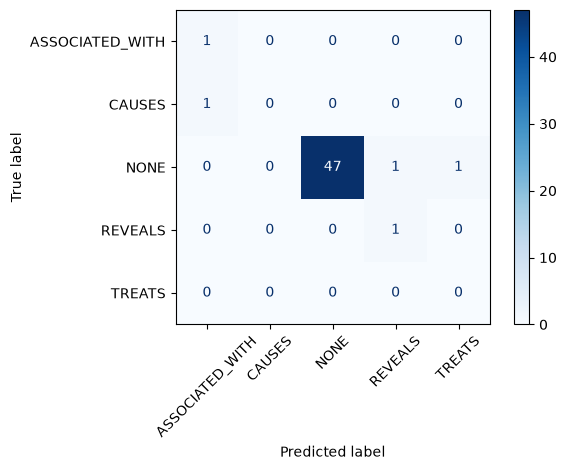

In [78]:
best_row = df_rel.sort_values('macroF1_relações', ascending=False).iloc[0]
print("melhor:", dict(best_row))
best_key = (best_row.modelo, int(best_row.ngram_max))
pred = fitted[best_key].predict(pairs_test)
print(classification_report(pairs_test.rule, pred, zero_division=0, digits=3))
ConfusionMatrixDisplay.from_predictions(pairs_test.rule, pred, xticks_rotation=45, cmap='Blues')
plt.tight_layout(); plt.show()

### Padrões aprendidos

Coeficientes da regressão logística sobre n-grams do trecho entre as entidades.

In [79]:
lr_key = ('LogReg', max(2, best_key[1]))
lr_pipe = fitted[lr_key]
names = lr_pipe.named_steps['feat'].get_feature_names_out()
clf = lr_pipe.named_steps['clf']
btw_idx = [i for i, n in enumerate(names) if n.startswith('between__') and not re.search(r'\d', n)]
top = {}
for ci, cls in enumerate(clf.classes_):
    if cls == 'NONE':
        continue
    order = sorted(btw_idx, key=lambda i: -clf.coef_[ci][i])[:8]
    top[cls] = [names[i].replace('between__', '') for i in order]
display(pd.DataFrame(dict([(k, pd.Series(v)) for k, v in top.items()])))

,ASSOCIATED_WITH,REVEALS,TREATS
0,accompanied,indicated,for
1,accompanied by,scan,treatment
2,associated,imaging,treatment with
3,associated with,imaging showed,with
4,by,showed,low
5,with,by,was
6,in,upper,( hr
7,intermittent,revealed,hr


In [80]:
# Gatilhos novos: pares que o modelo classifica como relação com confiança alta e as regras NÃO cobrem
proba = lr_pipe.predict_proba(pairs_test)
cls = list(lr_pipe.classes_)
none_i = cls.index('NONE')
pairs_test['ml'] = [cls[i] for i in proba.argmax(1)]
pairs_test['ml_conf'] = proba.max(1)
new = pairs_test[(pairs_test.rule == 'NONE') & (pairs_test.ml != 'NONE') & (pairs_test.ml_conf >= 0.6)]
print(f"{len(new)} pares com relação prevista pelo ML e sem gatilho nas regras")

def ngrams_of(text, nmax=3):
    w = text.split()
    return [' '.join(w[i:i + n]) for n in range(1, nmax + 1) for i in range(len(w) - n + 1)]

c_new, c_all = Counter(), Counter()
for t in pairs_test.between: c_all.update(set(ngrams_of(t)))
for t in new.between: c_new.update(set(ngrams_of(t)))
N_new, N_all = max(len(new), 1), len(pairs_test)
cand = pd.DataFrame([{'ngram': g, 'count_novos': c, 'lift': (c / N_new) / (c_all[g] / N_all)}
                     for g, c in c_new.items() if c >= 5 and not all(x in STOP or not x.isalpha() for x in g.split())])
if len(cand):
    display(cand.sort_values(['lift', 'count_novos'], ascending=False).head(25).round(2))
display(new[['e1', 'between', 'e2', 'ml', 'ml_conf']].sample(min(10, len(new)), random_state=SEED).round(2))

1 pares com relação prevista pelo ML e sem gatilho nas regras


,e1,between,e2,ml,ml_conf
40,pneumonia,that required,antibiotic,TREATS,0.76


### Conjunto ouro anotado manualmente

Gera um CSV estratificado (pares com relação por regra, pares novos do ML, pares `NONE`) para anotar `gold_label` com um dos rótulos: `CAUSED_BY, CAUSES, ASSOCIATED_WITH, REVEALS, TREATS, NONE`. Com ~150 pares anotados é possível comparar **regras × ML** de forma honesta.

In [81]:
GOLD_PATH = os.path.join(OUT_DIR, 'gold_relations.csv')
if not os.path.exists(GOLD_PATH):
    parts = [pairs_test[pairs_test.rule != 'NONE'].sample(n=min(50, (pairs_test.rule != 'NONE').sum()), random_state=SEED),
             new.sample(n=min(50, len(new)), random_state=SEED),
             (lambda d: d.sample(n=min(50, len(d)), random_state=SEED))(pairs_test[(pairs_test.rule == 'NONE') & (pairs_test.ml == 'NONE')])]
    g = pd.concat(parts).drop_duplicates(['case_id', 'sentence', 'e1', 'e2'])
    g['gold_label'] = ''
    g[['case_id', 'sentence', 'e1', 't1', 'e2', 't2', 'rule', 'ml', 'ml_conf', 'gold_label']].to_csv(GOLD_PATH, index=False)
    print("arquivo criado:", GOLD_PATH, "-> preencha gold_label e rode esta célula de novo")
else:
    g = pd.read_csv(GOLD_PATH).fillna({'gold_label': ''})
    g = g[g.gold_label != '']
    if len(g) == 0:
        print("preencha a coluna gold_label em", GOLD_PATH)
    else:
        for col in ('rule', 'ml'):
            print(f"--- {col} vs ouro (n={len(g)}) ---")
            print(classification_report(g.gold_label, g[col], zero_division=0, digits=3))

--- rule vs ouro (n=51) ---
                 precision    recall  f1-score   support

ASSOCIATED_WITH      1.000     1.000     1.000         1
         CAUSES      1.000     1.000     1.000         1
           NONE      0.958     0.979     0.968        47
        REVEALS      0.000     0.000     0.000         1
         TREATS      0.000     0.000     0.000         1

       accuracy                          0.941        51
      macro avg      0.592     0.596     0.594        51
   weighted avg      0.922     0.941     0.932        51

--- ml vs ouro (n=51) ---
                 precision    recall  f1-score   support

ASSOCIATED_WITH      0.500     1.000     0.667         1
         CAUSES      0.000     0.000     0.000         1
           NONE      0.979     0.979     0.979        47
        REVEALS      0.000     0.000     0.000         1
         TREATS      1.000     1.000     1.000         1

       accuracy                          0.941        51
      macro avg      0.496   

## 6. Construção do grafo de conhecimento

Duas versões sobre o conjunto de teste:

- **Regras (Parte 1 melhorada)**: entidades do gazetteer completo e relações por gatilho.
- **ML**: entidades do CRF (treinado com os rótulos do gazetteer completo) e relações do classificador (confiança ≥ 0.6).

Nós de entidade são compartilhados entre pacientes (id = `tipo:stems`). Relações entidade–entidade são agregadas com contagem de casos.

In [82]:
# CRF final: treina com o gazetteer completo (rótulos 'gold') e a melhor configuração
lvl, pmi = CONFIGS[best_name]
train_final = [s for s in sents_train if s['gold'] or rng.random() < NEG_KEEP]
crf_final = train_crf(train_final, 'gold', lvl, pmi)
for s, P in zip(sents_test, predict_crf(crf_final, sents_test, lvl, pmi)):
    s['ml'] = P
print("CRF final treinado:", best_name)

CRF final treinado: uni


In [83]:
PATIENT_REL = {'Diagnosis': 'DIAGNOSED_WITH', 'Symptom': 'HAS_SYMPTOM', 'Exam': 'UNDERWENT_EXAM', 'Treatment': 'TREATED_BY'}
UNIT = r"(?:%|mmhg|mm|cm|bpm|[a-zµμ]{1,4}/[a-zµμ0-9]{1,4}(?:\^?\d+)?|x\s*10\^?\d+/?[a-zµμ]*)"
VALUE_RE = re.compile(r"(\d+(?:\.\d+)?)\s*(" + UNIT + r")(?![a-z])", re.I)
REL_CONF = 0.6

def node_key(t, toks):
    return f"{t}:" + ' '.join(stem(x[0]) for x in toks)

def orient(label, t1, t2, n1, n2):
    if label == 'CAUSES':          return n1, n2, 'CAUSES'
    if label == 'CAUSED_BY':       return n2, n1, 'CAUSES'
    if label == 'ASSOCIATED_WITH': return n1, n2, 'ASSOCIATED_WITH'
    if label == 'REVEALS' and (t1 == 'Exam') != (t2 == 'Exam'):
        return (n1, n2, 'REVEALS') if t1 == 'Exam' else (n2, n1, 'REVEALS')
    if label == 'TREATS' and (t1 == 'Treatment') != (t2 == 'Treatment'):
        return (n1, n2, 'TREATS') if t1 == 'Treatment' else (n2, n1, 'TREATS')
    return None

def build_graph(sents, df_cases, spans_key, mode, rel_model=None):
    nodes, edges = {}, defaultdict(lambda: {'count': 0, 'cases': set()})
    for r in df_cases.itertuples():
        nodes[f'P:{r.case_id}'] = {'node_id': f'P:{r.case_id}', 'type': 'Patient', 'label': f'Case {r.case_id}',
                                   'attributes': json.dumps({'age': getattr(r, 'age', None), 'gender': getattr(r, 'gender', None)}, default=str)}
    def add_edge(src, tgt, rel, case):
        e = edges[(src, tgt, rel)]; e['count'] += 1; e['cases'].add(case)

    for s in sents:
        pid = f"P:{s['case_id']}"
        for a, b, t, *_ in s[spans_key]:
            toks = s['tokens'][a:b]; nid = node_key(t, toks)
            nodes.setdefault(nid, {'node_id': nid, 'type': t, 'label': ' '.join(x[0].lower() for x in toks), 'attributes': '{}'})
            add_edge(pid, nid, PATIENT_REL[t], s['case_id'])
            if t == 'Exam':   # resultado numérico logo após o exame, antes da próxima entidade
                nxt = [e[0] for e in s[spans_key] if e[0] >= b]
                stop = s['tokens'][min(nxt)][1] if nxt else len(s['text'])
                m = VALUE_RE.search(s['text'][s['tokens'][b - 1][2]:min(stop, s['tokens'][b - 1][2] + 80)])
                if m:
                    rid = f"R:{s['case_id']}:{nid}:{m.group(1)}{m.group(2).lower()}"
                    nodes.setdefault(rid, {'node_id': rid, 'type': 'ExamResult', 'label': f'{m.group(1)} {m.group(2)}',
                                           'attributes': json.dumps({'value': m.group(1), 'unit': m.group(2)})})
                    add_edge(nid, rid, 'HAS_RESULT', s['case_id'])

    pairs = make_pairs(sents, spans_key)
    if len(pairs):
        if mode == 'rules':
            pairs['label'] = pairs['rule']
        else:
            pr = rel_model.predict_proba(pairs); cl = list(rel_model.classes_)
            pairs['label'] = [cl[i] if p >= REL_CONF else 'NONE' for i, p in zip(pr.argmax(1), pr.max(1))]
        for r in pairs[pairs.label != 'NONE'].itertuples():
            s = sents[r.sent_idx]
            n1 = node_key(r.t1, s['tokens'][r.span1[0]:r.span1[1]]); n2 = node_key(r.t2, s['tokens'][r.span2[0]:r.span2[1]])
            o = orient(r.label, r.t1, r.t2, n1, n2)
            if o and o[0] != o[1]:
                add_edge(*o, r.case_id)
    df_n = pd.DataFrame(nodes.values())
    df_e = pd.DataFrame([{'source': k[0], 'target': k[1], 'relation': k[2], 'count': v['count'], 'n_cases': len(v['cases']), 'method': mode}
                         for k, v in edges.items()])
    return df_n, df_e

nodes_rules, edges_rules = build_graph(sents_test, df_test, 'gold', 'rules')
nodes_ml, edges_ml = build_graph(sents_test, df_test, 'ml', 'ml', rel_model=lr_pipe)
print(f"regras: {len(nodes_rules)} nós, {len(edges_rules)} arestas | ML: {len(nodes_ml)} nós, {len(edges_ml)} arestas")

regras: 119 nós, 132 arestas | ML: 97 nós, 108 arestas


In [84]:
import networkx as nx

PAT_REL = set(PATIENT_REL.values()) | {'HAS_RESULT'}
def graph_stats(n, e):
    ee = e[~e.relation.isin(PAT_REL)]
    G = nx.DiGraph(); G.add_edges_from(zip(e.source, e.target))
    ent = n[~n.type.isin(['Patient', 'ExamResult'])]
    return {'nós de entidade': len(ent), **{f'  {t}': int((ent.type == t).sum()) for t in ENT_TYPES},
            'arestas paciente→entidade': int(e.relation.isin(PATIENT_REL.values()).sum()),
            'arestas entidade↔entidade': len(ee),
            **{f'  {r}': int((ee.relation == r).sum()) for r in sorted(ee.relation.unique())},
            'grau médio': round(2 * G.number_of_edges() / max(G.number_of_nodes(), 1), 2),
            'densidade': round(nx.density(G), 5),
            'componentes fracamente conexos': nx.number_weakly_connected_components(G)}

st = pd.DataFrame({'regras': graph_stats(nodes_rules, edges_rules), 'ML': graph_stats(nodes_ml, edges_ml)}).fillna(0)
display(st)

def ee_set(e): return set(map(tuple, e[~e.relation.isin(PAT_REL)][['source', 'target', 'relation']].values))
def ent_set(n): return set(n[~n.type.isin(['Patient', 'ExamResult'])].node_id)
A, B = ent_set(nodes_rules), ent_set(nodes_ml); Ea, Eb = ee_set(edges_rules), ee_set(edges_ml)
print(f"Jaccard de nós de entidade: {len(A & B) / len(A | B):.3f} | só ML: {len(B - A)} | só regras: {len(A - B)}")
print(f"Jaccard de arestas entidade↔entidade: {len(Ea & Eb) / max(len(Ea | Eb), 1):.3f} | só ML: {len(Eb - Ea)} | só regras: {len(Ea - Eb)}")

,regras,ML
nós de entidade,73.00000,60.00000
Diagnosis,5.00000,5.00000
Symptom,20.00000,19.00000
Exam,36.00000,25.00000
Treatment,12.00000,11.00000
arestas paciente→entidade,94.00000,80.00000
arestas entidade↔entidade,3.00000,2.00000
ASSOCIATED_WITH,1.00000,1.00000
CAUSES,1.00000,0.00000
REVEALS,1.00000,0.00000


Jaccard de nós de entidade: 0.662 | só ML: 7 | só regras: 20
Jaccard de arestas entidade↔entidade: 0.250 | só ML: 1 | só regras: 2


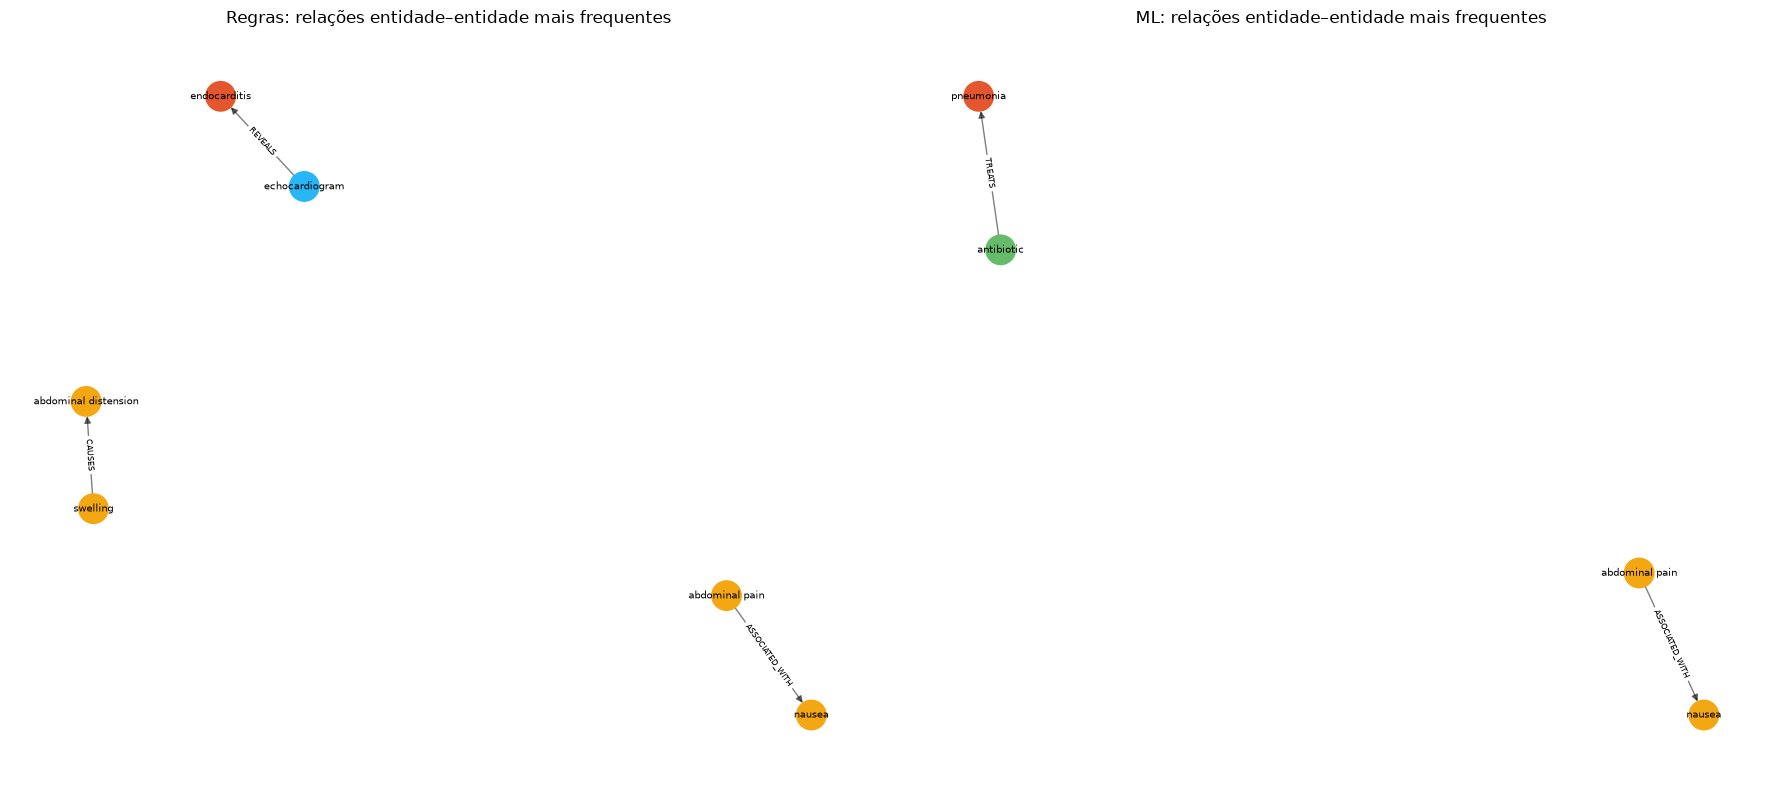

In [85]:
COLORS = {'Patient': '#9aa5b1', 'Diagnosis': '#e4572e', 'Symptom': '#f3a712', 'Exam': '#29b6f6', 'Treatment': '#66bb6a', 'ExamResult': '#ce93d8'}

def draw_graph(n, e, title, case_id=None, top_n=40, ax=None):
    ax = ax or plt.gca()
    if case_id:
        pid = f'P:{case_id}'
        sub = e[(e.source == pid) | (e.target == pid)]
        keep = set(sub.source) | set(sub.target)
        sub = e[e.source.isin(keep) & e.target.isin(keep)]
    else:
        sub = e[~e.relation.isin(PAT_REL)].sort_values('n_cases', ascending=False).head(top_n)
    G = nx.DiGraph()
    meta = n.set_index('node_id')
    for r in sub.itertuples():
        G.add_edge(r.source, r.target, rel=r.relation)
    pos = nx.spring_layout(G, seed=SEED, k=1.2 / max(math.sqrt(max(len(G), 1)), 1))
    nx.draw_networkx_nodes(G, pos, node_color=[COLORS[meta.loc[x, 'type']] for x in G], node_size=450, ax=ax)
    nx.draw_networkx_edges(G, pos, arrows=True, alpha=0.5, ax=ax, node_size=450)
    nx.draw_networkx_labels(G, pos, {x: str(meta.loc[x, 'label'])[:22] for x in G}, font_size=7, ax=ax)
    nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, 'rel'), font_size=6, ax=ax)
    ax.set_title(title); ax.axis('off')

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
draw_graph(nodes_rules, edges_rules, 'Regras: relações entidade–entidade mais frequentes', ax=axes[0])
draw_graph(nodes_ml, edges_ml, 'ML: relações entidade–entidade mais frequentes', ax=axes[1])
plt.tight_layout(); plt.show()

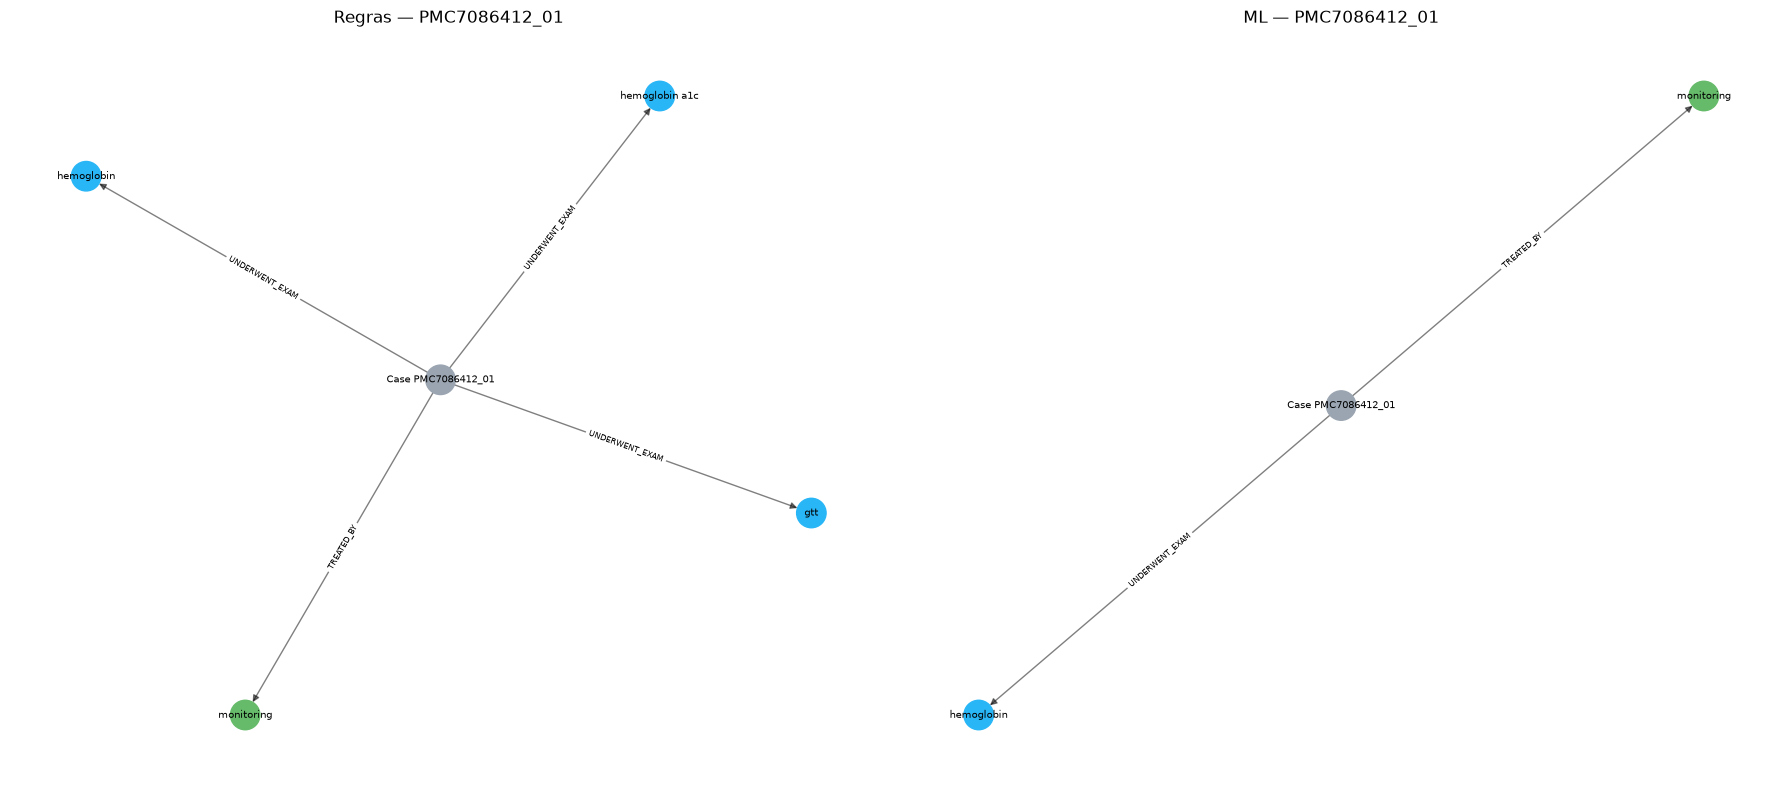

In [103]:
# Subgrafo de um caso, nas duas abordagens
cid = df_test.case_id.iloc[4]
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
draw_graph(nodes_rules, edges_rules, f'Regras — {cid}', case_id=cid, ax=axes[0])
draw_graph(nodes_ml, edges_ml, f'ML — {cid}', case_id=cid, ax=axes[1])
plt.tight_layout(); plt.show()

def to_mermaid(nodes, edges) -> str:
    lines = ["flowchart LR"]
    ids = lambda x: re.sub(r'\W', '_', x)
    for n in nodes.itertuples():
        lines.append(f'  {ids(n.node_id)}["{n.type}<br/>{str(n.label).replace(chr(34), chr(39))}"]')
    for e in edges.itertuples():
        lines.append(f'  {ids(e.source)} -->|{e.relation}| {ids(e.target)}')
    return "\n".join(lines)

In [87]:
# Exportação
nodes_rules.to_csv(f'{OUT_DIR}/nodes_rules.csv', index=False); edges_rules.to_csv(f'{OUT_DIR}/edges_rules.csv', index=False)
nodes_ml.to_csv(f'{OUT_DIR}/nodes_ml.csv', index=False);       edges_ml.to_csv(f'{OUT_DIR}/edges_ml.csv', index=False)
df_ner.round(4).to_csv(f'{OUT_DIR}/results_ner.csv'); df_rel.round(4).to_csv(f'{OUT_DIR}/results_relations.csv', index=False)
df_cand.to_csv(f'{OUT_DIR}/ngram_entity_candidates.csv', index=False)
print("arquivos salvos em", OUT_DIR)

arquivos salvos em ../../data/processed
